## DATA PREPROCESSING 


### 1. Thư viện




In [11]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
TABLES = ROOT / "reports" / "03_data_preprocessing" / "tables"
FIGURES = ROOT / "reports" / "03_data_preprocessing" / "figures"
ARTIFACTS = ROOT / "results" / "preprocessors"
for folder in (TABLES, FIGURES, ARTIFACTS):
    folder.mkdir(parents=True, exist_ok=True)

print("Project:", ROOT)
print("scikit-learn:", sklearn.__version__)
print("Input:", DATA)

Project: C:\homework\Machine Learning\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\ĐỒ ÁN CUỐI KỲ NHÓM 4
scikit-learn: 1.7.2
Input: C:\homework\Machine Learning\SGU26K2_MayHoc_DCT124C3_Nhom4_RT-IoT2022\ĐỒ ÁN CUỐI KỲ NHÓM 4\data\processed


### 2. Kiểm tra dữ liệu

Kiểm tra số hàng, cột, nhãn, schema và tính duy nhất của vector đặc trưng giữa các tập.

In [12]:
TARGET = "Attack_type"
splits = {name: pd.read_csv(DATA / f"{name}.csv", low_memory=False) for name in ("train", "validation", "test")}
train, val, test = (splits[k] for k in ("train", "validation", "test"))
assert all(TARGET in df.columns for df in splits.values())
assert list(train.columns) == list(val.columns) == list(test.columns)
assert all(df[TARGET].notna().all() for df in splits.values())
assert train[TARGET].nunique() == 12
assert set(val[TARGET]).issubset(set(train[TARGET]))
assert set(test[TARGET]).issubset(set(train[TARGET]))
assert all(df.duplicated().sum() == 0 for df in splits.values())

feature_columns = [c for c in train.columns if c != TARGET]
assert "Unnamed: 0" not in feature_columns
assert "bwd_URG_flag_count" not in feature_columns
assert len(feature_columns) == 82

split_summary = pd.DataFrame({"split": list(splits), "rows": [len(df) for df in splits.values()], "features": len(feature_columns), "classes": [df[TARGET].nunique() for df in splits.values()]})
display(split_summary)
split_summary.to_csv(TABLES / "01_input_split_summary.csv", index=False)

hashes = {k: set(pd.util.hash_pandas_object(df[feature_columns], index=False)) for k, df in splits.items()}
overlap = {"train_validation": len(hashes["train"] & hashes["validation"]), "train_test": len(hashes["train"] & hashes["test"]), "validation_test": len(hashes["validation"] & hashes["test"])}
assert all(v == 0 for v in overlap.values()), overlap
print("Vector trùng giữa các tập:", overlap)

,split,rows,features,classes
0,train,82536,82,12
1,validation,17686,82,12
2,test,17687,82,12


Vector trùng giữa các tập: {'train_validation': 0, 'train_test': 0, 'validation_test': 0}


### 3. Phân loại đặc trưng và xác nhận không có dữ liệu thiếu


In [13]:
X_train = train[feature_columns].copy()
X_val = val[feature_columns].copy()
X_test = test[feature_columns].copy()
y_train_raw = train[TARGET].copy()
y_val_raw = val[TARGET].copy()
y_test_raw = test[TARGET].copy()

numeric_cols = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X_train.select_dtypes(exclude=np.number).columns.tolist()
assert set(categorical_cols) == {"proto", "service"}, categorical_cols
assert len(numeric_cols) + len(categorical_cols) == len(feature_columns)

quality_rows = []
for name, frame in (("train", X_train), ("validation", X_val), ("test", X_test)):
    missing = int(frame.isna().sum().sum())
    nonfinite = int((~np.isfinite(frame[numeric_cols].to_numpy(dtype=np.float64))).sum())
    quality_rows.append({"split": name, "missing_values": missing, "nonfinite_numeric_values": nonfinite})
    assert missing == 0, f"{name}: dữ liệu thiếu, cần kiểm tra trước khi tiền xử lý"
    assert nonfinite == 0, f"{name}: xuất hiện NaN hoặc Inf"

quality = pd.DataFrame(quality_rows)
quality.to_csv(TABLES / "02_data_quality_checks.csv", index=False)
schema = pd.DataFrame({"feature": feature_columns, "dtype_train": [str(X_train[c].dtype) for c in feature_columns], "group": ["numeric" if c in numeric_cols else "categorical" for c in feature_columns]})
schema.to_csv(TABLES / "03_feature_schema.csv", index=False)
print("Số đặc trưng số:", len(numeric_cols), "| phân loại:", len(categorical_cols))
display(quality)
display(schema.tail(8))

Số đặc trưng số: 80 | phân loại: 2


,split,missing_values,nonfinite_numeric_values
0,train,0,0
1,validation,0,0
2,test,0,0


,feature,dtype_train,group
74,idle.min,float64,numeric
75,idle.max,float64,numeric
76,idle.tot,float64,numeric
77,idle.avg,float64,numeric
78,idle.std,float64,numeric
79,fwd_init_window_size,int64,numeric
80,bwd_init_window_size,int64,numeric
81,fwd_last_window_size,int64,numeric


### 4. One-hot encoding

- **Random Forest:** giữ nguyên 80 đặc trưng số; One-Hot Encoding cho proto và service.
- **MLP:** StandardScaler cho 80 đặc trưng số; cùng One-Hot Encoding.

In [14]:
rf_preprocessor = ColumnTransformer(
    [("num", "passthrough", numeric_cols),
     ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), categorical_cols)],
    remainder="drop", sparse_threshold=0
)
mlp_preprocessor = ColumnTransformer(
    [("num", StandardScaler(), numeric_cols),
     ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), categorical_cols)],
    remainder="drop", sparse_threshold=0
)
print("RF:", rf_preprocessor)
print("MLP:", mlp_preprocessor)

RF: ColumnTransformer(sparse_threshold=0,
                  transformers=[('num', 'passthrough',
                                 ['id.orig_p', 'id.resp_p', 'flow_duration',
                                  'fwd_pkts_tot', 'bwd_pkts_tot',
                                  'fwd_data_pkts_tot', 'bwd_data_pkts_tot',
                                  'fwd_pkts_per_sec', 'bwd_pkts_per_sec',
                                  'flow_pkts_per_sec', 'down_up_ratio',
                                  'fwd_header_size_tot', 'fwd_header_size_min',
                                  'fwd_header_size_max', 'bwd_header_size_tot',
                                  'bwd_...
                                  'flow_RST_flag_count', 'fwd_PSH_flag_count',
                                  'bwd_PSH_flag_count', 'flow_ACK_flag_count',
                                  'fwd_URG_flag_count', 'flow_CWR_flag_count',
                                  'flow_ECE_flag_count', 'fwd_pkts_payload.min',
                 

### 5. fit_transform trên Train

Để tránh Data Leakage, các tham số StandardScaler và danh mục One-Hot được học từ Train. Validation/Test chỉ được transform bằng pipeline đã học.

In [15]:
X_rf = {"train": rf_preprocessor.fit_transform(X_train)}
X_mlp = {"train": mlp_preprocessor.fit_transform(X_train)}
for key, frame in (("validation", X_val), ("test", X_test)):
    X_rf[key] = rf_preprocessor.transform(frame)
    X_mlp[key] = mlp_preprocessor.transform(frame)

for family, matrices in (("RF", X_rf), ("MLP", X_mlp)):
    print(f"{family}:", {k: v.shape for k, v in matrices.items()})
    assert len({v.shape[1] for v in matrices.values()}) == 1
    assert all(np.isfinite(v).all() for v in matrices.values())

rf_names = rf_preprocessor.get_feature_names_out()
mlp_names = mlp_preprocessor.get_feature_names_out()
assert list(rf_names) == list(mlp_names)
assert len(rf_names) == X_rf["train"].shape[1]
assert TARGET not in rf_names
pd.DataFrame({"index": range(len(rf_names)), "transformed_feature": rf_names}).to_csv(TABLES / "04_transformed_feature_names.csv", index=False)
print("Tổng chiều sau One-Hot:", len(rf_names))
print("10 đặc trưng đầu:", rf_names[:10].tolist())
print("10 đặc trưng cuối:", rf_names[-10:].tolist())

RF: {'train': (82536, 92), 'validation': (17686, 92), 'test': (17687, 92)}
MLP: {'train': (82536, 92), 'validation': (17686, 92), 'test': (17687, 92)}
Tổng chiều sau One-Hot: 92
10 đặc trưng đầu: ['num__id.orig_p', 'num__id.resp_p', 'num__flow_duration', 'num__fwd_pkts_tot', 'num__bwd_pkts_tot', 'num__fwd_data_pkts_tot', 'num__bwd_data_pkts_tot', 'num__fwd_pkts_per_sec', 'num__bwd_pkts_per_sec', 'num__flow_pkts_per_sec']
10 đặc trưng cuối: ['cat__proto_udp', 'cat__service_-', 'cat__service_dhcp', 'cat__service_dns', 'cat__service_http', 'cat__service_irc', 'cat__service_mqtt', 'cat__service_ntp', 'cat__service_ssh', 'cat__service_ssl']


### 6. Mã hóa 12 nhãn đầu ra bằng LabelEncoder


In [16]:
label_encoder = LabelEncoder()
y_encoded = {"train": label_encoder.fit_transform(y_train_raw), "validation": label_encoder.transform(y_val_raw), "test": label_encoder.transform(y_test_raw)}
label_mapping = pd.DataFrame({"class_id": np.arange(len(label_encoder.classes_)), "Attack_type": label_encoder.classes_})
label_mapping.to_csv(TABLES / "05_label_mapping.csv", index=False)
assert len(label_mapping) == 12
for key in splits:
    assert len(y_encoded[key]) == len(X_rf[key]) == len(X_mlp[key])
    assert np.array_equal(label_encoder.inverse_transform(y_encoded[key]), splits[key][TARGET].to_numpy())
display(label_mapping)

,class_id,Attack_type
0,0,ARP_poisioning
1,1,DDOS_Slowloris
2,2,DOS_SYN_Hping
3,3,MQTT_Publish
4,4,Metasploit_Brute_Force_SSH
5,5,NMAP_FIN_SCAN
6,6,NMAP_OS_DETECTION
7,7,NMAP_TCP_scan
8,8,NMAP_UDP_SCAN
9,9,NMAP_XMAS_TREE_SCAN


### 7. Kiểm định tiền xử lý và trực quan hóa

Kiểm tra StandardScaler trên Train: các cột có phương sai khác 0 sẽ có mean gần 0 và std gần 1. Không kỳ vọng Validation/Test có mean bằng 0 vì không fit scaler trên hai tập này. Đặc trưng nhị phân/cột hằng được xử lý theo quy tắc riêng của scaler.

In [17]:
mlp_num = X_mlp["train"][:, :len(numeric_cols)]
rf_num = X_rf["train"][:, :len(numeric_cols)]
means = mlp_num.mean(axis=0)
stds = mlp_num.std(axis=0)
nonconstant = rf_num.std(axis=0) > 1e-10
assert np.max(np.abs(means)) < 1e-4
assert np.allclose(stds[nonconstant], 1.0, atol=1e-4)
assert np.allclose(stds[~nonconstant], 0.0, atol=1e-4)

stats = pd.DataFrame({"feature": numeric_cols, "rf_train_mean": rf_num.mean(axis=0), "rf_train_std": rf_num.std(axis=0), "mlp_train_mean": means, "mlp_train_std": stds})
stats.to_csv(TABLES / "06_scaling_diagnostics.csv", index=False)
display(stats.head(12).round(4))
print("Mean tuyệt đối lớn nhất sau scaling:", float(np.max(np.abs(means))))
print("Tỷ lệ hữu hạn RF/MLP: 100%")

,feature,rf_train_mean,rf_train_std,mlp_train_mean,mlp_train_std
0,id.orig_p,35029.3958,18940.5813,-0.0,1.0
1,id.resp_p,1054.5238,5379.5177,-0.0,1.0
2,flow_duration,3.7336,131.7205,0.0,1.0
3,fwd_pkts_tot,2.2288,20.1982,-0.0,1.0
4,bwd_pkts_tot,1.9366,37.4231,-0.0,1.0
5,fwd_data_pkts_tot,1.4253,17.7856,-0.0,1.0
6,bwd_data_pkts_tot,0.8444,36.6649,0.0,1.0
7,fwd_pkts_per_sec,352239.0851,371516.9137,0.0,1.0
8,bwd_pkts_per_sec,352191.9653,371554.6337,0.0,1.0
9,flow_pkts_per_sec,704431.0504,743068.0678,-0.0,1.0


Mean tuyệt đối lớn nhất sau scaling: 1.1500469505688865e-14
Tỷ lệ hữu hạn RF/MLP: 100%


### 8. Biểu đồ minh họa tác động của scaling và số chiều sau One-hot Endcoding


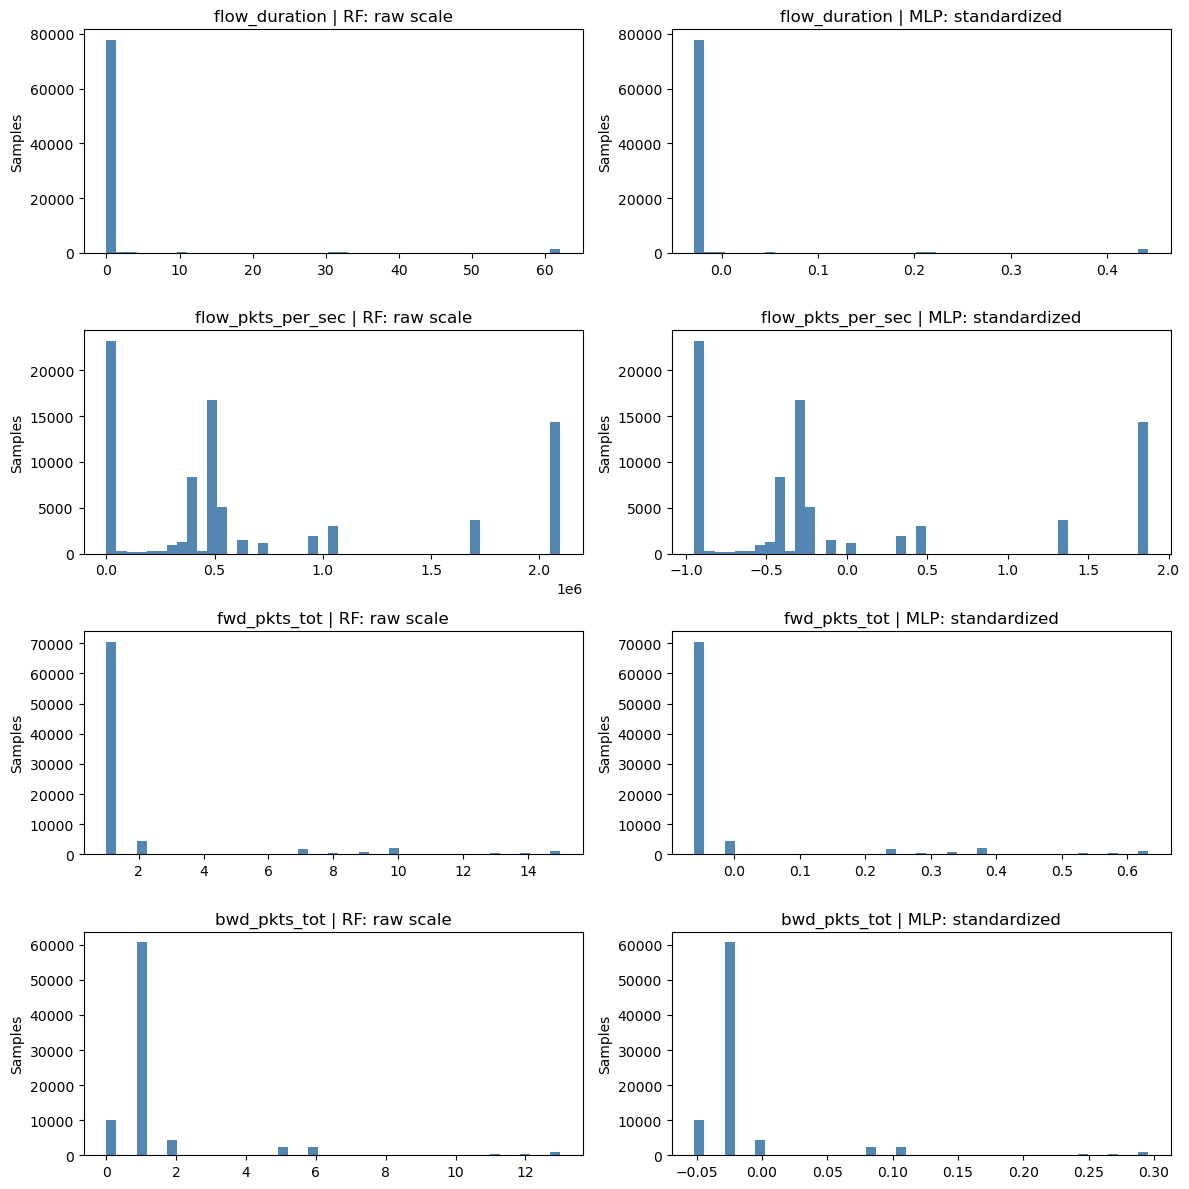

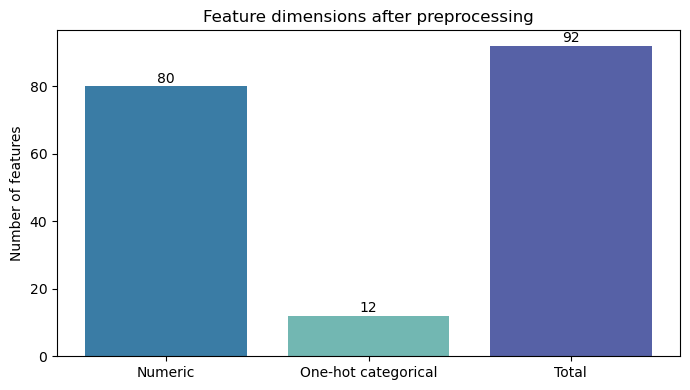

In [18]:
candidate = ["flow_duration", "flow_pkts_per_sec", "fwd_pkts_tot", "bwd_pkts_tot"]
selected = [c for c in candidate if c in numeric_cols]
fig, axes = plt.subplots(len(selected), 2, figsize=(12, 3 * len(selected)))
for i, col in enumerate(selected):
    j = numeric_cols.index(col)
    for ax, values, title in ((axes[i,0], X_rf["train"][:,j], "RF: raw scale"), (axes[i,1], X_mlp["train"][:,j], "MLP: standardized")):
        low, high = np.percentile(values, [1, 99])
        ax.hist(np.clip(values, low, high), bins=45, color="#3572A5", alpha=.85)
        ax.set_title(f"{col} | {title}")
        ax.set_ylabel("Samples")
fig.tight_layout()
fig.savefig(FIGURES / "01_scaling_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7,4))
ax.bar(["Numeric", "One-hot categorical", "Total"], [len(numeric_cols), len(rf_names)-len(numeric_cols), len(rf_names)], color=["#3A7CA5", "#72B7B2", "#5661A6"])
for i, n in enumerate([len(numeric_cols), len(rf_names)-len(numeric_cols), len(rf_names)]):
    ax.text(i, n+1, str(n), ha="center")
ax.set_ylabel("Number of features")
ax.set_title("Feature dimensions after preprocessing")
fig.tight_layout()
fig.savefig(FIGURES / "02_feature_dimensions.png", dpi=160, bbox_inches="tight")
plt.show()

### 9. Xuất data

In [19]:
joblib.dump(rf_preprocessor, ARTIFACTS / "rf_preprocessor.joblib", compress=3)
joblib.dump(mlp_preprocessor, ARTIFACTS / "mlp_preprocessor.joblib", compress=3)
joblib.dump(label_encoder, ARTIFACTS / "label_encoder.joblib", compress=3)

csv_outputs = []
for family, matrices in (("rf", X_rf), ("mlp", X_mlp)):
    for split, arr in matrices.items():
        frame = pd.DataFrame(arr, columns=rf_names)
        frame[TARGET] = y_encoded[split].astype(np.int16)
        destination = DATA / f"{family}_{split}.csv"
        frame.to_csv(destination, index=False, float_format="%.9g")
        csv_outputs.append({"file": destination.name, "rows": len(frame), "columns": frame.shape[1]})

output_manifest = pd.DataFrame(csv_outputs)
output_manifest.to_csv(TABLES / "07_csv_output_manifest.csv", index=False)
summary = {
    "source": "Step 2 fixed stratified split (70/15/15)",
    "rows": {k: len(v) for k, v in splits.items()},
    "input_features": len(feature_columns),
    "numeric_features": len(numeric_cols),
    "categorical_features": categorical_cols,
    "transformed_features": len(rf_names),
    "classes": label_encoder.classes_.tolist(),
    "missing_values": quality.set_index("split")["missing_values"].to_dict(),
    "nonfinite_numeric_values": quality.set_index("split")["nonfinite_numeric_values"].to_dict(),
    "imputation": "none; fail-fast quality checks",
    "rf_numeric": "passthrough; no scaling",
    "mlp_numeric": "StandardScaler fitted on train only",
    "categorical": "OneHotEncoder(handle_unknown=ignore) fitted on train only",
    "target": "LabelEncoder fitted on train only",
    "output_format": "CSV",
    "overlap": overlap,
    "sklearn_version": sklearn.__version__
}
(ROOT / "results" / "step3_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
display(output_manifest)
print("Saved CSV and Joblib artifacts.")

,file,rows,columns
0,rf_train.csv,82536,93
1,rf_validation.csv,17686,93
2,rf_test.csv,17687,93
3,mlp_train.csv,82536,93
4,mlp_validation.csv,17686,93
5,mlp_test.csv,17687,93


Saved CSV and Joblib artifacts.


### 10. Kiểm tra khả năng nạp lại và tính nhất quán của CSV



In [20]:
rf_loaded = joblib.load(ARTIFACTS / "rf_preprocessor.joblib")
mlp_loaded = joblib.load(ARTIFACTS / "mlp_preprocessor.joblib")
labels_loaded = joblib.load(ARTIFACTS / "label_encoder.joblib")
assert np.allclose(rf_loaded.transform(X_val.iloc[:50]), X_rf["validation"][:50])
assert np.allclose(mlp_loaded.transform(X_val.iloc[:50]), X_mlp["validation"][:50])
assert np.array_equal(labels_loaded.transform(y_test_raw.iloc[:50]), y_encoded["test"][:50])
for family, matrices in (("rf", X_rf), ("mlp", X_mlp)):
    for split, arr in matrices.items():
        saved = pd.read_csv(DATA / f"{family}_{split}.csv")
        assert saved.shape == (len(arr), len(rf_names) + 1)
        assert saved.columns[-1] == TARGET
        assert saved[TARGET].to_numpy().tolist() == y_encoded[split].tolist()
        assert np.allclose(saved.iloc[:50, :-1].to_numpy(), arr[:50], rtol=2e-5, atol=1e-5)
print("PASS: CSV, RF/MLP pipelines và LabelEncoder đã được xác minh.")

PASS: CSV, RF/MLP pipelines và LabelEncoder đã được xác minh.
